# Actividad 3. Capa de visualización temática

# Paso 1. Instalar las librerías

In [1]:
%pip install pandas numpy geopandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Paso 2. Importo las librerías y ubico la raíz del proyecto

In [2]:
import sys
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Detecto la raíz del proyecto, que es la carpeta que contiene
# src/ y notebooks/.
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

print('Raíz del proyecto:', RAIZ)
print('¿Existe src/capa_tematica.py?', (RAIZ / 'src' / 'capa_tematica.py').exists())

Raíz del proyecto: C:\Users\itzel\PROYECTO_DESASTRES
¿Existe src/capa_tematica.py? True


# Paso 3. Cargo el dataset integrado y validado

In [3]:
from src.config import DATASET_INTEGRADO, MAPA_SHP

df = pd.read_csv(DATASET_INTEGRADO, low_memory=False)
print(f'Eventos cargados : {len(df):,}')
print(f'Territorios (ISO): {df["ISO"].nunique()}')
print(f'Periodo          : {int(df["Start Year"].min())} – {int(df["Start Year"].max())}')
df[[
    'DisNo.', 'Disaster Type', 'ISO', 'Start Year',
    'Total Deaths', 'Total Affected', "Total Damage, Adjusted ('000 MXN)",
]].head()

Eventos cargados : 10,907
Territorios (ISO): 220
Periodo          : 2000 – 2026


,DisNo.,Disaster Type,ISO,Start Year,Total Deaths,Total Affected,"Total Damage, Adjusted ('000 MXN)"
0,2025-0303-ECU,Earthquake,ECU,2025,NaN,8512.0,NaN
1,2026-0153-KEN,Flood,KEN,2026,59.0,27.0,NaN
2,2025-0750-AFG,Earthquake,AFG,2025,2200.0,1304600.0,3744000.0
3,2026-0305-AFG,Flood,AFG,2026,18.0,73309.0,NaN
4,2024-0962-AGO,Epidemic,AGO,2025,776.0,27728.0,NaN


# Paso 4. Reviso las variables temáticas que definí

variables:

* Número de desastres (`eventos`)
* Fallecidos totales (`fallecidos`)
* Personas afectadas (`afectados`)
* Daño económico ajustado (`dano_ajustado`)
* Fallecidos promedio por evento (`prom_fallecidos`)
* Afectados promedio por evento (`prom_afectados`)

In [4]:
from src.capa_tematica import VARIABLES

# Armo una tabla para ver de un vistazo qué variables tengo definidas.
tabla_variables = pd.DataFrame([
    {
        'clave': clave,
        'etiqueta': definicion['etiqueta'],
        'unidad': definicion['unidad'],
        'escala sugerida': definicion['escala_sugerida'],
        'categoria': definicion['categoria'],
    }
    for clave, definicion in VARIABLES.items()
])
tabla_variables

,clave,etiqueta,unidad,escala sugerida,categoria
0,eventos,Número de desastres,eventos,lineal,recuento
1,fallecidos,Fallecidos totales,personas,log,impacto humano
2,afectados,Personas afectadas,personas,log,impacto humano
3,dano_ajustado,Daño económico ajustado,MXN,log,impacto económico
4,prom_fallecidos,Fallecidos promedio por evento,personas/evento,log,intensidad
5,prom_afectados,Afectados promedio por evento,personas/evento,log,intensidad


# Paso 5. Recupero la integración geográfica de la Actividad 2

Cargo los límites territoriales (Natural Earth 110m) y aplico las
mismas decisiones que tomé en la Actividad 2:

* **Equivalencias de código:** `PSE → PSX`, `SSD → SDS`.
* **Fusiones cartográficas:** `CYN → CYP` y `SOL → SOM`, sin sumar
  indicadores porque EM-DAT no los desglosa.
* **Territorios sin indicadores:** `SAH, FLK, GRL, ATF, BRN, ATA, CYN,
  SOL, KOS` los conservo SIN datos para no atribuir eventos de un
  territorio a otro sin evidencia.

In [5]:
from src.capa_tematica import preparar_mapa

# Preparo el mapa y compruebo que no quedaron códigos duplicados.
mapa = preparar_mapa()
print(f'Unidades cartográficas: {len(mapa)}')
print(f'Códigos duplicados    : {mapa["codigo"].duplicated().sum()}')
print(f'Geometrías válidas    : {int(mapa.geometry.is_valid.sum())} de {len(mapa)}')
mapa[['codigo', 'ADMIN', 'CONTINENT']].head()

Unidades cartográficas: 175
Códigos duplicados    : 0
Geometrías válidas    : 175 de 175


,codigo,ADMIN,CONTINENT
0,AFG,Afghanistan,Asia
1,AGO,Angola,Africa
2,ALB,Albania,Europe
3,ARE,United Arab Emirates,Asia
4,ARG,Argentina,South America


# Paso 6. Agrego los indicadores por territorio

EM-DAT registra eventos individuales, pero para colorear el mapa
necesito **un registro por territorio**: cuento eventos, sumo
fallecidos, afectados y daño, y calculo los promedios por evento.

El daño económico del dataset ya viene en **miles de pesos
mexicanos**: la conversión desde USD se hace antes, en `src/moneda.py`.
Aquí solo lo multiplico por 1000 para dejarlo en pesos.

In [6]:
from src.capa_tematica import agregar_indicadores

# Agrego los eventos a nivel de territorio y ordeno por número de eventos.
agregado = agregar_indicadores(df)
print(f'Territorios con indicadores: {len(agregado)}')
agregado.sort_values('eventos', ascending=False).head(10)

Territorios con indicadores: 220


,codigo,eventos,fallecidos,afectados,tipos_distintos,dano_ajustado,prom_fallecidos,prom_afectados,cobertura_dano
34,CHN,675,116358.0,1.771309e+09,11,1.543352e+13,172.38,2624162.09,63.9
206,USA,660,11649.0,1.047048e+08,9,4.356707e+13,17.65,158643.64,76.1
85,IND,436,93320.0,1.148026e+09,10,3.485151e+12,214.04,2633088.17,26.6
84,IDN,425,191257.0,4.828843e+07,8,8.069660e+11,450.02,113619.84,20.9
151,PHL,406,28309.0,2.586417e+08,9,7.304565e+11,69.73,637048.43,56.9
212,VNM,209,5962.0,4.987050e+07,7,6.867472e+11,28.53,238614.81,54.1
94,JPN,191,24064.0,5.753346e+06,7,1.253250e+13,125.99,30122.23,51.8
0,AFG,182,19157.0,3.745632e+07,7,1.391770e+10,105.26,205803.93,6.0
148,PAK,174,90221.0,1.029587e+08,10,1.248439e+12,518.51,591716.57,14.9
26,BRA,173,4731.0,5.885381e+07,8,1.199824e+12,27.35,340195.44,40.5


## Verificación: compruebo que los totales no se pierden

Antes de seguir quiero asegurarme de que al agregar no perdí ni
dupliqué ningún evento. Comparo los totales del dataset integrado con
los de mi capa temática.

In [7]:
# Comparo los totales del dataset integrado con los de la capa
# temática: deben coincidir exactamente.
comparacion = pd.DataFrame({
    'en el dataset integrado': [
        len(df),
        df['Total Deaths'].sum(),
        df['Total Affected'].sum(),
    ],
    'en la capa temática': [
        agregado['eventos'].sum(),
        agregado['fallecidos'].sum(),
        agregado['afectados'].sum(),
    ],
}, index=['eventos', 'fallecidos', 'afectados'])
comparacion['coincide'] = (
    comparacion['en el dataset integrado'] == comparacion['en la capa temática']
)
comparacion

,en el dataset integrado,en la capa temática,coincide
eventos,1.090700e+04,1.090700e+04,True
fallecidos,1.737592e+06,1.737592e+06,True
afectados,4.903434e+09,4.903434e+09,True


# Paso 7. Uno la cartografía con los indicadores

`construir_capa` hace la unión (merge) entre los 175 territorios y los
indicadores. A los territorios sin eventos les queda `NaN`, y les marco
una **disponibilidad** explícita para que la interfaz distinga "sin
datos" de "cero desastres".

In [8]:
from src.capa_tematica import construir_capa

# Uno el mapa con los indicadores agregados.
capa, tabla = construir_capa(df)

print(f'Unidades cartográficas : {len(capa)}')
print(f'Con indicadores        : {int(capa["eventos"].notna().sum())}')
print()
print('Disponibilidad de datos:')
capa['disponibilidad'].value_counts()

Unidades cartográficas : 175
Con indicadores        : 168

Disponibilidad de datos:


disponibilidad
Con indicadores asociados    168
Sin indicadores directos       7
Name: count, dtype: int64

### Territorios que dejé sin indicadores

Decidí conservar estos territorios sin datos de forma intencional. La
ausencia de indicadores **no** significa ausencia de desastres:
refleja que EM-DAT no registra eventos que cumplan sus criterios de
inclusión para ese territorio en el periodo analizado.

In [9]:
# Reviso qué territorios quedaron sin indicadores y por qué.
sin_datos = capa[capa['disponibilidad'] != 'Con indicadores asociados']
sin_datos[['codigo', 'nombre', 'disponibilidad', 'observacion']]

,codigo,nombre,disponibilidad,observacion
4,ATA,Antártida,Sin indicadores directos,No se identificaron registros directos en EM-DAT.
21,BRN,Brunéi,Sin indicadores directos,No se identificaron coincidencias directas de ...
67,GRL,Groenlandia,Sin indicadores directos,No se confirmó un desglose independiente de Di...
82,FLK,Islas Malvinas,Sin indicadores directos,No se identificaron registros directos por nom...
92,KOS,Kosovo,Sin indicadores directos,No se asignan automáticamente los totales de S...
152,SAH,Sáhara Occidental,Sin indicadores directos,No se asignan eventos de Marruecos o Mauritani...
157,ATF,Tierras Australes y Antárticas Francesas,Sin indicadores directos,No se identificaron registros independientes e...


# Paso 8. Calculo los estadísticos para las escalas

La interfaz necesita saber el rango de cada variable para construir la
rampa de color. Como las variables de impacto (fallecidos, afectados,
daño) tienen distribuciones muy sesgadas, calculo **percentiles** y
recorto el máximo de la escala a **p99**: así un solo país no me
aplasta el contraste del resto del mapa.

In [10]:
from src.capa_tematica import calcular_estadisticos

# Calculo los estadísticos de cada variable sobre los territorios con dato.
estadisticos = pd.DataFrame({
    clave: calcular_estadisticos(capa[clave]) for clave in VARIABLES
}).T
estadisticos[['n', 'min', 'p50', 'p90', 'p99', 'max', 'media']].round(2)

,n,min,p50,p90,p99,max,media
eventos,168.0,1.0,3.650000e+01,1.286000e+02,5.099200e+02,6.750000e+02,6.326000e+01
fallecidos,168.0,0.0,1.125500e+03,2.228180e+04,1.601543e+05,2.405750e+05,1.033438e+04
afectados,168.0,0.0,1.704829e+06,3.350164e+07,5.521386e+08,1.771309e+09,2.916461e+07
dano_ajustado,168.0,0.0,2.296809e+10,8.703330e+11,1.348984e+13,4.356707e+13,6.388571e+11
prom_fallecidos,168.0,0.0,2.886000e+01,2.340900e+02,2.286810e+03,3.306250e+03,1.242300e+02
prom_afectados,168.0,0.0,5.292618e+04,4.217079e+05,1.713649e+06,2.633088e+06,1.749941e+05


## Verificación: por qué recorto la escala en p99

Comparo el máximo real con el p99 para justificar el recorte. La
diferencia muestra cuánto se aplastaría el contraste si usara el
máximo real.

In [11]:
# Comparo el máximo real con el p99 que uso en la escala.
comparacion_escalas = pd.DataFrame({
    'máximo real': estadisticos['max'],
    'p99 (escala usada)': estadisticos['p99'],
    'factor de recorte': (estadisticos['max'] / estadisticos['p99']).round(1),
})
comparacion_escalas

,máximo real,p99 (escala usada),factor de recorte
eventos,6.750000e+02,5.099200e+02,1.3
fallecidos,2.405750e+05,1.601543e+05,1.5
afectados,1.771309e+09,5.521386e+08,3.2
dano_ajustado,4.356707e+13,1.348984e+13,3.2
prom_fallecidos,3.306250e+03,2.286812e+03,1.4
prom_afectados,2.633088e+06,1.713649e+06,1.5


# Paso 9. Genero la evidencia visual de la capa

Hago una primera comprobación de que mi agregación es correcta: si el
top de territorios por número de desastres corresponde a países grandes
y con larga historia de registros EM-DAT, voy por buen camino.

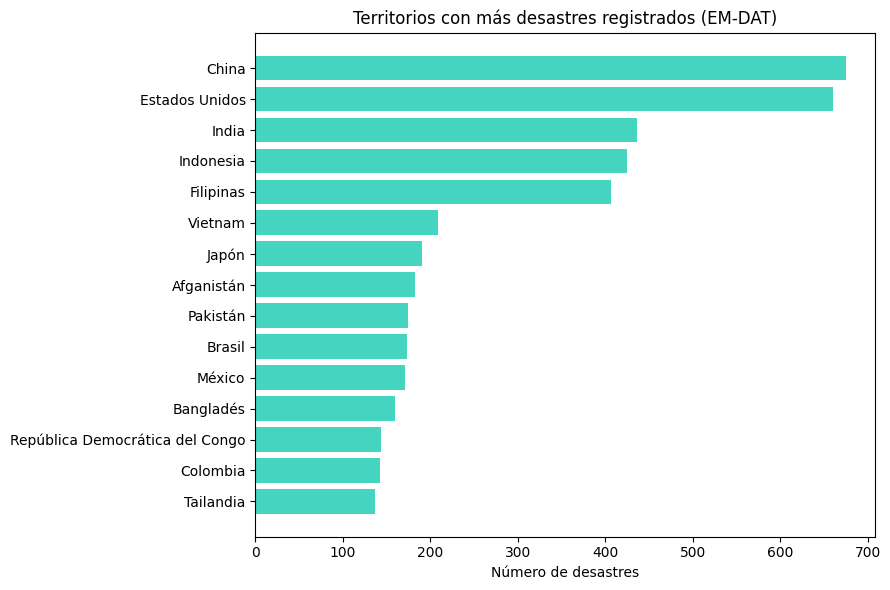

In [12]:
# Tomo los 15 territorios con más desastres para graficarlos.
top = capa.dropna(subset=['eventos']).nlargest(15, 'eventos')

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top['nombre'][::-1], top['eventos'][::-1], color='#45d4bf')
ax.set_title('Territorios con más desastres registrados (EM-DAT)')
ax.set_xlabel('Número de desastres')
plt.tight_layout()

# Guardo la gráfica como evidencia para el reporte.
carpeta_graficas = RAIZ / 'resultados' / 'graficas' / 'capa_tematica'
carpeta_graficas.mkdir(parents=True, exist_ok=True)
plt.savefig(carpeta_graficas / '08_top_desastres_notebook.png', dpi=150)
plt.show()

## Distribución de los valores por variable

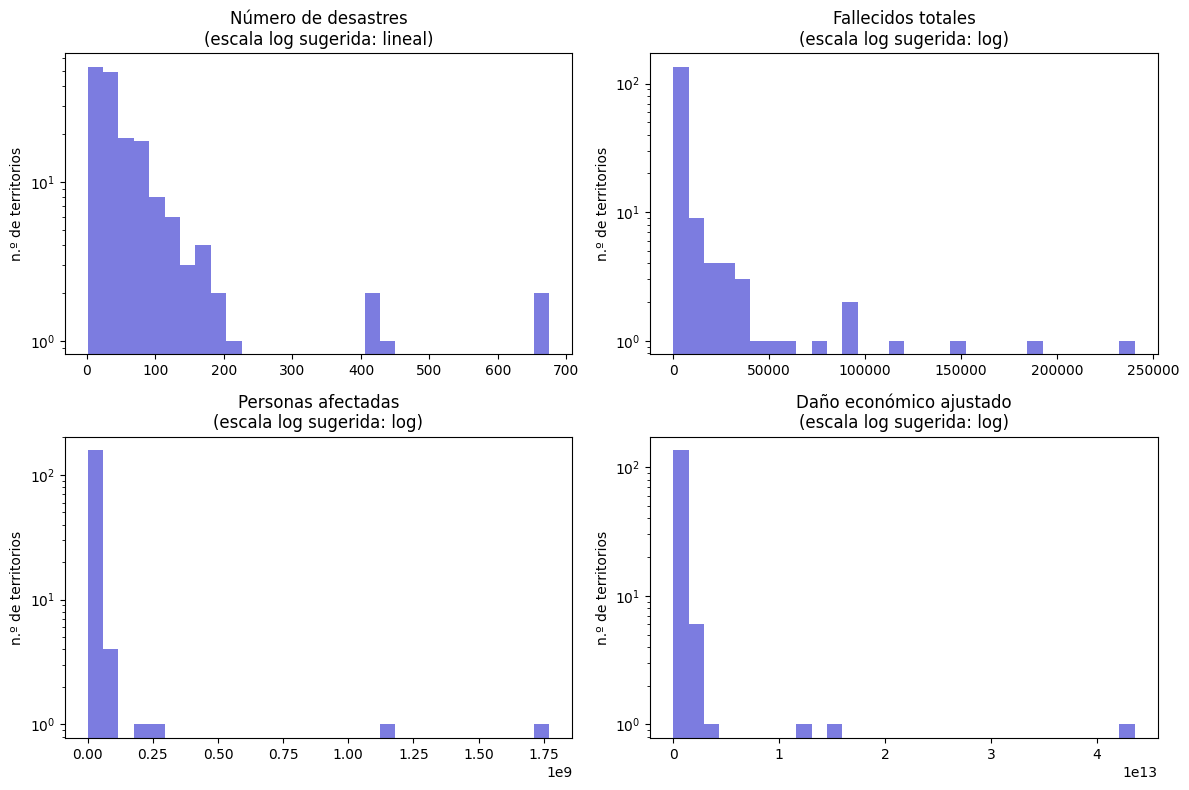

In [13]:
# Reviso cómo se distribuyen las cuatro variables principales.
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for eje, clave in zip(ejes.ravel(), ['eventos', 'fallecidos', 'afectados', 'dano_ajustado']):
    valores = capa[clave].dropna()
    eje.hist(valores[valores > 0], bins=30, color='#7c7ce0')
    eje.set_title(f'{VARIABLES[clave]["etiqueta"]}\n(escala log sugerida: '
                  f'{VARIABLES[clave]["escala_sugerida"]})')
    eje.set_yscale('log')
    eje.set_ylabel('n.º de territorios')
plt.tight_layout()
plt.savefig(carpeta_graficas / '09_distribucion_variables.png', dpi=150)
plt.show()

# Paso 10. Exporto los archivos que consume la aplicación web

La aplicación no ejecuta Python: lee un **GeoJSON** con la geometría y
los indicadores, más un **JSON de metadatos** con la descripción de
cada variable y sus estadísticos.

In [14]:
# Ejecuto el motor completo para exportar la capa y los metadatos.
import importlib
import src.capa_tematica as motor

importlib.reload(motor)
motor.main()

Leyendo dataset integrado…


  Eventos: 10,907 | Territorios EM-DAT: 220
Construyendo la capa temática…
  Unidades cartográficas: 175 | con indicadores: 168


  GeoJSON: C:\Users\itzel\PROYECTO_DESASTRES\app\datos\paises.geojson
  Metadatos: C:\Users\itzel\PROYECTO_DESASTRES\app\datos\metadatos.json
  Evidencia: C:\Users\itzel\PROYECTO_DESASTRES\resultados\tablas\resumen_capa_tematica.csv

Resumen por variable (territorios con datos):
  Número de desastres              n=168  máx=675.00  mediana=36.50
  Fallecidos totales               n=168  máx=240,575.00  mediana=1,125.50
  Personas afectadas               n=168  máx=1,771,309,413.00  mediana=1,704,829.00
  Daño económico ajustado          n=168  máx=43,567,068,376,000.00  mediana=22,968,088,000.00
  Fallecidos promedio por evento   n=168  máx=3,306.25  mediana=28.86
  Afectados promedio por evento    n=168  máx=2,633,088.17  mediana=52,926.18

Listo. La capa de visualización temática está preparada.


## Compruebo los archivos que acabo de generar

In [15]:
import json

# Reviso el tamaño de los archivos y el contenido de los metadatos.
ruta_geojson = RAIZ / 'app' / 'datos' / 'paises.geojson'
ruta_metadatos = RAIZ / 'app' / 'datos' / 'metadatos.json'

for ruta in (ruta_geojson, ruta_metadatos):
    print(f'{ruta.relative_to(RAIZ)}  →  {ruta.stat().st_size / 1024:.0f} KB')

metadatos = json.loads(ruta_metadatos.read_text(encoding='utf-8'))
print()
print('Territorios :', metadatos['n_territorios'])
print('Eventos     :', f"{metadatos['n_eventos']:,}")
print('Periodo     :', metadatos['periodo'])

app\datos\paises.geojson  →  517 KB
app\datos\metadatos.json  →  4 KB

Territorios : 175
Eventos     : 10,907
Periodo     : {'inicio': 2000, 'fin': 2026}


# Paso 11. Recursos visuales de la capa temática

La capa temática la escribí en `app/js/capa_tematica.js`. Los cuatro
recursos visuales del enunciado los implementé así:

1. **Coloración** — capa `fill` (`relleno-coloreado`) con una expresión
   de color que interpola el valor de la variable sobre la rampa.
2. **Intensidad de color** — un control que ajusta la saturación de la
   rampa (0–100 %) sin cambiar la variable.
3. **Elevación** — capa `fill-extrusion` (`relleno-relieve`) cuya altura
   es proporcional al valor de la variable.
4. **Deformación de la superficie** — el mismo relieve actúa como
   superficie continua sobre el globo 3D.

In [16]:
# Estas son las propiedades que expongo en el GeoJSON y que consume
# el frontend.
propiedades = [
    p for p in capa.drop(columns='geometry').columns
    if p not in ('disponibilidad', 'observacion')
]
print('Propiedades expuestas al GeoJSON:')
for p in propiedades:
    print('  ·', p)

Propiedades expuestas al GeoJSON:
  · codigo
  · nombre
  · nombre_original
  · continente
  · eventos
  · fallecidos
  · afectados
  · dano_ajustado
  · prom_fallecidos
  · prom_afectados
  · tipos_desastre
  · cobertura_dano


# Paso 12. Cómo ejecutar la aplicación web

La aplicación usa `fetch()` para leer el GeoJSON, así que **tengo que
servirla por HTTP** (no puedo abrir `index.html` con doble clic).

Desde la raíz del proyecto, en una terminal:

```bash
python -m src.servir_app
```

En la celda siguiente solo compruebo que todos los archivos de la
aplicación están presentes antes de abrirla.

In [17]:
# Compruebo que no me falta ningún archivo de la aplicación.
archivos_app = [
    'index.html',
    'css/estilos.css',
    'js/config.js',
    'js/escalas.js',
    'js/leyenda.js',
    'js/estado.js',
    'js/capa_tematica.js',
    'js/app.js',
    'datos/paises.geojson',
    'datos/metadatos.json',
]
for relativo in archivos_app:
    existe = (RAIZ / 'app' / relativo).exists()
    print(('OK  ' if existe else 'FALTA'), relativo)

OK   index.html
OK   css/estilos.css
OK   js/config.js
OK   js/escalas.js
OK   js/leyenda.js
OK   js/estado.js
OK   js/capa_tematica.js
OK   js/app.js
OK   datos/paises.geojson
OK   datos/metadatos.json


In [18]:
# Reviso las capturas que ya tengo generadas.
carpeta_capturas = RAIZ / 'resultados' / 'graficas' / 'capa_tematica'
capturas = sorted(carpeta_capturas.glob('*.png'))
print(f'Capturas disponibles: {len(capturas)}')
for c in capturas:
    print('  ·', c.name)

Capturas disponibles: 9
  · 01_globo_eventos.png
  · 02_globo_elevacion.png
  · 03_globo_deformacion.png
  · 04_globo_dano_economico.png
  · 05_combinado_eventos_fallecidos.png
  · 06_plano_mexico.png
  · 07_interfaz_completa.png
  · 08_top_desastres_notebook.png
  · 09_distribucion_variables.png


#Para ejecutar la app desde aquí

In [19]:
import subprocess
import sys
from pathlib import Path

# Detecta la raíz del proyecto aunque estés en notebooks/
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

# Lanza el servidor sin abrir el navegador
subprocess.Popen(
    [sys.executable, "-X", "utf8", "-m", "src.servir_app", "--sin-navegador"],
    cwd=str(RAIZ)
)

print("Servidor lanzado. Abre manualmente: http://127.0.0.1:8000/index.html")

Servidor lanzado. Abre manualmente: http://127.0.0.1:8000/index.html
